# Part 1: Clustering Analysis
Author: Britney Ball

Assignment Details: 
- Select and apply at least two different clustering algorithms.
- Justify your choice of algorithms and parameter settings.
- Visualize the clustering results using appropriate plots.
- Interpret the clusters in the context of your project domain — what do they represent? Are they meaningful or actionable?
- Compare the results between methods. Discuss similarities, differences, and possible reasons for discrepancies.

## Purpose and approach

This analysis uses GH Archive-derived repository activity from 2024 to identify and describe groups with similar observed behavior. K-means and DBSCAN are compared because they define clusters differently: one partitions observations around centroids, while the other finds dense neighborhoods and can leave observations unassigned. The analysis is descriptive and exploratory; a cluster label is not a direct measure of software quality or archival risk.

## 1. Data preparation and feature engineering

The modeling population contains repositories active in at least three months of 2024 (7,890 of 62,627 in the current data). Fourteen activity features measured during 2024 are used as clustering inputs. The later outcome, `inactive_next_365d`, is excluded from those inputs and is consulted only after fitting to help characterize the resulting groups.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Read the merged GH Archive-based dataset. This relative path assumes
# the notebook's working directory is notebooks/.
df = pd.read_csv("../data/merged_dataset.csv")

# Select pre-cutoff activity counts. Exclude inactive_next_365d because it
# describes the later outcome and will be used only to interpret clusters.
full_count = len(df)
df = df.loc[df["active_months_2024"] >= 3].copy()
df["days_since_last_push_at_cutoff"] = (
    df["days_since_last_push_at_cutoff"].fillna(366)
)

VOLUME = [
    "push_events_2024", "issue_events_2024", "issue_comment_events_2024",
    "pull_request_events_2024", "review_events_2024", "release_events_2024",
    "stars_received_2024", "fork_events_2024",
]
BREADTH = ["distinct_actors_2024", "active_days_2024", "active_months_2024"]
ENGAGEMENT = [
    "issue_events_2024", "issue_comment_events_2024",
    "pull_request_events_2024", "review_events_2024",
]
TREND = ["qualifying_events_h1_2024", "qualifying_events_h2_2024"]
RECENCY = ["days_since_last_push_at_cutoff"]

FEATURES = VOLUME + BREADTH + TREND + RECENCY

# Fail on nonnumeric values rather than silently converting them to missing.
raw = df[FEATURES].apply(pd.to_numeric, errors="raise")

print(f"Selected repositories: {len(df):,} of {full_count:,}")
print("Missing values:\n", raw.isna().sum())

# Investigate missing or negative counts before clustering.
if raw.isna().any().any():
    raise ValueError("Selected features contain missing values.")

if (raw < 0).any().any():
    raise ValueError("Selected count features contain negative values.")

# Log-transform to reduce skew, then standardize each transformed feature.
# X retains the same row order as df.
X = StandardScaler().fit_transform(np.log1p(raw))

print("Clustering matrix:", X.shape)

Selected repositories: 7,890 of 62,627
Missing values:
 push_events_2024                  0
issue_events_2024                 0
issue_comment_events_2024         0
pull_request_events_2024          0
review_events_2024                0
release_events_2024               0
stars_received_2024               0
fork_events_2024                  0
distinct_actors_2024              0
active_days_2024                  0
active_months_2024                0
qualifying_events_h1_2024         0
qualifying_events_h2_2024         0
days_since_last_push_at_cutoff    0
dtype: int64
Clustering matrix: (7890, 14)


A missing value for `days_since_last_push_at_cutoff` represents no push in 2024 and is encoded as 366. The feature matrix is checked for nonnumeric, missing, or negative values before modeling. `log1p` reduces the influence of highly skewed activity counts, and standardization places the transformed features on comparable scales for distance calculations. The untransformed `raw` data is retained so cluster profiles can be reported in their original units.

### Algorithm rationale

K-means provides a centroid-based baseline for broad, relatively compact activity profiles, but requires the number of clusters to be specified. DBSCAN uses local density instead, does not require a cluster count, and can label points outside dense regions as noise. Applying both methods to the same standardized features makes their different assumptions visible. Neither method assigns a health label; cluster meaning must be assessed from the feature profiles and, separately, the later inactivity outcome.

## 2. K-means clustering

K-means minimizes the within-cluster sum of squared distances in the standardized feature space. Because its solution depends on K, models are fitted for K=1 through K=8 with 20 initializations and a fixed random seed. Inertia, sampled silhouette scores, and cluster sizes are considered together; none alone establishes that a particular K is correct.

### 2.1 Selecting the number of clusters


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(1, 9)
models = {}
results = []

for k in ks:
    model = KMeans(
        n_clusters=k,
        n_init=20,       # Try multiple initial centroid positions.
        random_state=42, # Make the results reproducible.
    )
    labels = model.fit_predict(X)
    models[k] = model

    # Silhouette requires at least two clusters.
    silhouette = np.nan
    if k >= 2:
        silhouette = silhouette_score(
            X,
            labels,
            sample_size=min(2000, len(X)),
            random_state=42,
        )

    sizes = pd.Series(labels).value_counts()
    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette,
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max(),
    })

results_df = pd.DataFrame(results).set_index("k")
display(results_df.round(3))

,inertia,silhouette,smallest_cluster,largest_cluster
k,,,,
1,110460.000,NaN,7890,7890
2,81374.560,0.475,995,6895
3,67231.719,0.285,778,5250
4,59816.015,0.218,753,3345
5,54325.854,0.226,311,3085
6,50919.537,0.233,220,3136
7,47848.463,0.230,197,2649
8,45217.138,0.236,201,2616


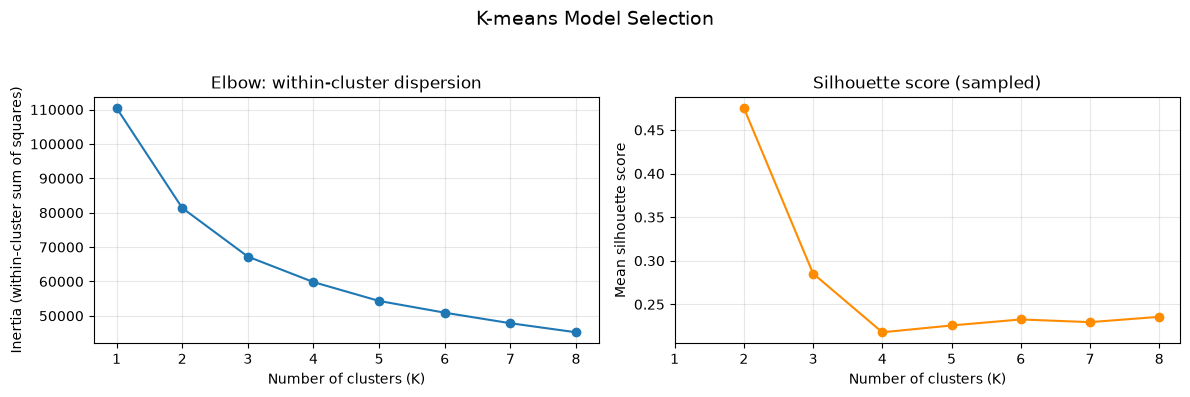

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("K-means Model Selection", fontsize=14)

axes[0].plot(results_df.index, results_df["inertia"], marker="o")
axes[0].set_title("Elbow: within-cluster dispersion")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_xticks(list(ks))
axes[0].grid(alpha=0.3)

axes[1].plot(
    results_df.index,
    results_df["silhouette"],
    marker="o",
    color="darkorange",
)
axes[1].set_title("Silhouette score (sampled)")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_xticks(list(ks))
axes[1].grid(alpha=0.3)

fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGURES_DIR / "kmeans_model_selection.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### 2.2 Fit and profile the selected K-means solution

The elbow and silhouette plots provide complementary evidence for choosing K. In the current results, K=2 has the largest tested silhouette score (0.475), while inertia shows diminishing improvement beyond the first split. The resulting cluster sizes are 6,895 and 995; the imbalance is reported explicitly so the smaller cluster is not mistaken for a similarly sized segment.

In [4]:
chosen_k = 2  # Replace after reviewing the plots and table.

kmeans = models[chosen_k]
df["kmeans"] = kmeans.labels_

print("Cluster sizes:")
print(df["kmeans"].value_counts().sort_index())

print("\nMedian values in original units:")
display(raw.groupby(df["kmeans"]).median().round(2))

print("\nFuture inactivity by cluster:")
display(
    df.groupby("kmeans")["inactive_next_365d"]
    .agg(repositories="size", inactivity_rate="mean")
    .round(3)
)

Cluster sizes:
kmeans
0    6895
1     995
Name: count, dtype: int64

Median values in original units:


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
kmeans,,,,,,,,,,,,,,
0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,15.0,4.0,23.0,12.0,66.0
1,81.0,8.0,27.0,39.0,7.0,0.0,5.0,3.0,8.0,51.0,10.0,119.0,98.0,24.0



Future inactivity by cluster:


,repositories,inactivity_rate
kmeans,,
0,6895,0.525
1,995,0.124


For K=2, the fitted groups contain 6,895 and 995 repositories. The smaller group has higher median event volume, breadth, and half-year activity, as well as a more recent median push; its future inactivity rate is lower (12.4% versus 52.5% for the larger group). This supports describing two activity profiles in this sample, but the post-cutoff rates are associations, not evidence that activity caused the outcome.

## 3. DBSCAN clustering

DBSCAN tests whether the standardized feature space contains dense neighborhoods and identifies observations outside them as noise. It uses Euclidean distance; `MIN_SAMPLES` is set to 28 (twice the 14 feature dimensions) as a transparent starting heuristic, while `EPS` sets the neighborhood radius. The k-distance curve supplies a candidate radius, and the sensitivity check examines nearby `EPS` values.

Feature count: 14
min_samples: 28
Zero k-distances: 0.0%


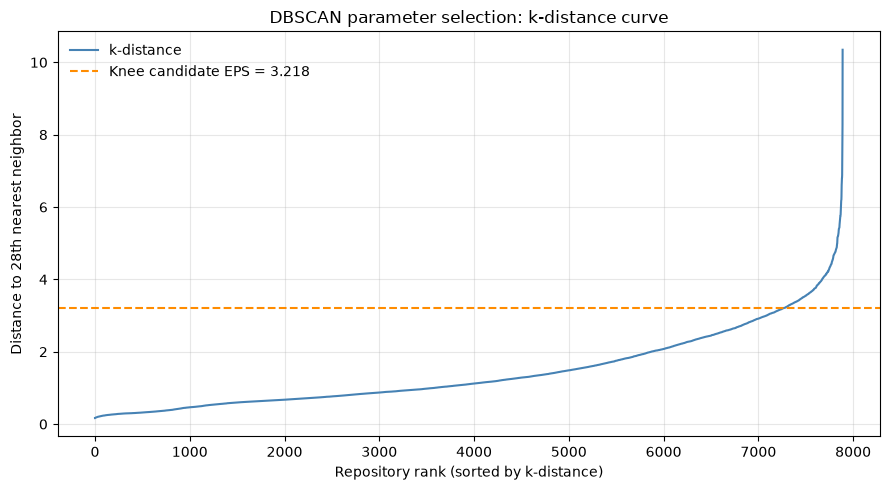

Knee candidate: 3.218325


In [5]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 2 * X.shape[1]

neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES,
    metric="euclidean",
).fit(X)

distances, _ = neighbors.kneighbors(X)
k_dist = np.sort(distances[:, -1])

print(f"Feature count: {X.shape[1]}")
print(f"min_samples: {MIN_SAMPLES}")
print(f"Zero k-distances: {(k_dist == 0).mean():.1%}")

if k_dist[-1] == k_dist[0]:
    raise ValueError("All k-distances are equal; inspect the feature matrix.")

x01 = np.linspace(0, 1, len(k_dist))
y01 = (k_dist - k_dist[0]) / (k_dist[-1] - k_dist[0])
knee = int(np.argmax(x01 - y01))
candidate_eps = float(k_dist[knee])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_dist, color="steelblue", linewidth=1.5, label="k-distance")
ax.axhline(
    candidate_eps,
    color="darkorange",
    linestyle="--",
    label=f"Knee candidate EPS = {candidate_eps:.3f}",
)
ax.set(
    xlabel="Repository rank (sorted by k-distance)",
    ylabel=f"Distance to {MIN_SAMPLES}th nearest neighbor",
    title="DBSCAN parameter selection: k-distance curve",
)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "dbscan_k_distance.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Knee candidate: {candidate_eps:.6f}")
if candidate_eps <= 0:
    print("The knee is zero; inspect positive distances before choosing eps.")

The bend in a sorted k-distance curve is a heuristic candidate for `EPS`, not a uniquely correct threshold. The next cell compares the selected radius with values 20% below and above it, reporting cluster count, noise count, noise fraction, and largest-cluster size. A useful setting should yield interpretable structure; reducing the noise count alone is not evidence of improved clustering.

In [6]:
# Enter the agreed positive value after inspecting the k-distance plot.
EPS = 3.218  # Knee candidate; review the sensitivity results before finalizing.

if not np.isfinite(EPS) or EPS <= 0:
    raise ValueError("EPS must be a finite positive number.")

def dbscan_labels(X, eps, min_samples, index):
    labels = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean",
    ).fit_predict(X)
    return pd.Series(labels, index=index, name="dbscan")

# df must be the same filtered population, in the same row order as X.
labels = dbscan_labels(X, EPS, MIN_SAMPLES, df.index)
df["dbscan"] = labels

rows = []
for candidate in [EPS * 0.8, EPS, EPS * 1.2]:
    candidate_labels = (
        labels if candidate == EPS
        else dbscan_labels(X, candidate, MIN_SAMPLES, df.index)
    )
    sizes = candidate_labels[candidate_labels != -1].value_counts()

    rows.append({
        "eps": candidate,
        "clusters": len(sizes),
        "noise_count": int((candidate_labels == -1).sum()),
        "noise_fraction": (candidate_labels == -1).mean(),
        "largest_cluster": int(sizes.max()) if not sizes.empty else 0,
    })

display(pd.DataFrame(rows).round(3))

,eps,clusters,noise_count,noise_fraction,largest_cluster
0,2.574,1,663,0.084,7227
1,3.218,1,188,0.024,7702
2,3.862,1,44,0.006,7846


All three tested radii produce one non-noise cluster. At `EPS = 3.218`, that cluster contains 7,702 repositories and 188 are classified as noise. Increasing `EPS` reduces the noise count from 663 to 44 across the tested range but does not reveal additional clusters. Under these settings, DBSCAN therefore provides a large dense group and a set of density outliers rather than a multi-group partition.

## 4. Visualizing cluster assignments

Principal component analysis (PCA) projects the standardized 14-feature matrix onto two axes for display; the clustering models themselves are fitted in the full feature space. Each point represents a repository, and color identifies its K-means or DBSCAN assignment, with DBSCAN noise distinguished. The first two components retain 59.1% of the variance, so the plot is a partial projection: apparent overlap or separation in two dimensions may not reflect the full-space distances.

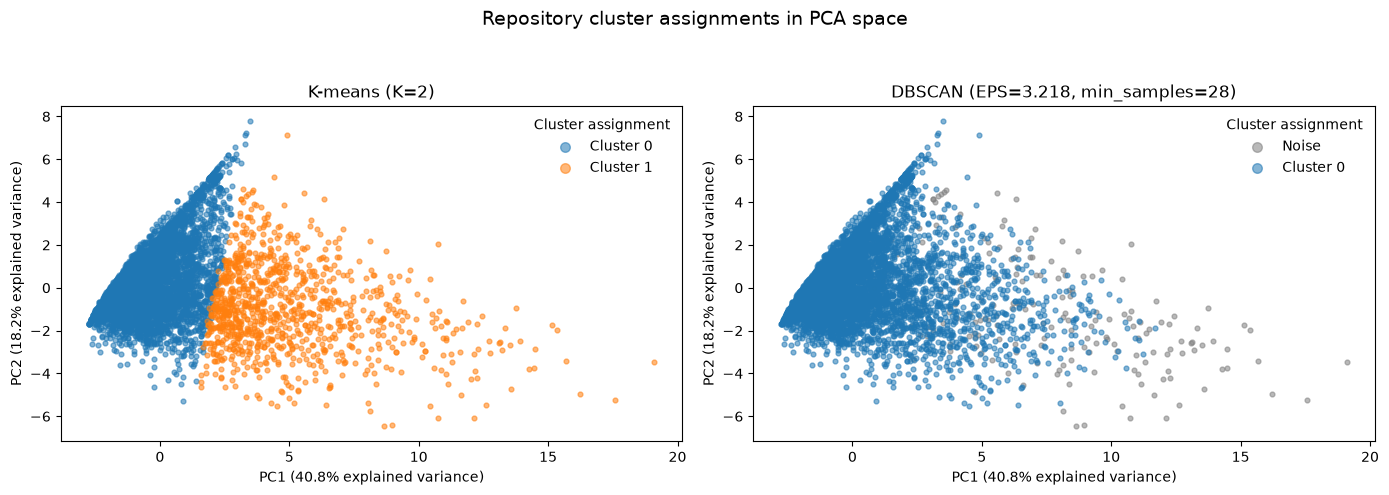

Variance represented: 59.1%


In [7]:
from sklearn.decomposition import PCA

if len(df) != len(X):
    raise ValueError("df and X have different numbers of rows.")

for method in ["kmeans", "dbscan"]:
    if method not in df or df[method].isna().any():
        raise ValueError(f"{method} labels are missing; rerun the fitting cell.")

pca = PCA(n_components=2)
xy = pca.fit_transform(X)
variance = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Repository cluster assignments in PCA space", fontsize=14)

for ax, method in zip(axes, ["kmeans", "dbscan"]):
    cluster_labels = df[method].to_numpy()

    for label in sorted(np.unique(cluster_labels)):
        mask = cluster_labels == label
        is_noise = method == "dbscan" and label == -1

        ax.scatter(
            xy[mask, 0],
            xy[mask, 1],
            s=12,
            alpha=0.55,
            color="gray" if is_noise else None,
            label="Noise" if is_noise else f"Cluster {label}",
        )

    if method == "kmeans":
        ax.set_title(f"K-means (K={chosen_k})")
    else:
        ax.set_title(f"DBSCAN (EPS={EPS:g}, min_samples={MIN_SAMPLES})")
    ax.set_xlabel(f"PC1 ({variance[0]:.1%} explained variance)")
    ax.set_ylabel(f"PC2 ({variance[1]:.1%} explained variance)")
    ax.legend(title="Cluster assignment", markerscale=2, frameon=False)

fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGURES_DIR / "cluster_assignments_pca.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Variance represented: {variance.sum():.1%}")

### Cluster profiles and subsequent inactivity

These summaries pair the median of each original 2024 feature with cluster size and the mean of `inactive_next_365d`. Medians provide a robust description of skewed activity counts, while the outcome rate allows a post-hoc comparison. Because the outcome is excluded from the feature matrix, these values describe an association rather than a model trained to predict future inactivity.

In [8]:
for method in ["kmeans", "dbscan"]:
    print(f"\n{method.upper()} — median feature values")
    display(df.groupby(method)[FEATURES].median().round(1))

    print(f"\n{method.upper()} — size and future inactivity")
    display(
        df.groupby(method)["inactive_next_365d"]
        .agg(repositories="size", inactivity_rate="mean")
        .round(3)
    )


KMEANS — median feature values


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
kmeans,,,,,,,,,,,,,,
0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,15.0,4.0,23.0,12.0,66.0
1,81.0,8.0,27.0,39.0,7.0,0.0,5.0,3.0,8.0,51.0,10.0,119.0,98.0,24.0



KMEANS — size and future inactivity


,repositories,inactivity_rate
kmeans,,
0,6895,0.525
1,995,0.124



DBSCAN — median feature values


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
dbscan,,,,,,,,,,,,,,
-1,302.0,40.5,99.5,110.0,27.5,3.0,12.0,10.5,18.0,144.0,12.0,496.0,383.0,9.5
0,36.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,16.0,4.0,26.0,15.0,61.0



DBSCAN — size and future inactivity


,repositories,inactivity_rate
dbscan,,
-1,188,0.170
0,7702,0.482


### Compare first-half and second-half activity

For each method, the bar charts compare cluster-level median qualifying-event counts in H1 and H2. The two counts are shown separately because an H2/H1 ratio is undefined when H1 is zero. Differences between bars describe typical group activity across half-years; they do not show every repository's individual trajectory or establish a cause for any change.

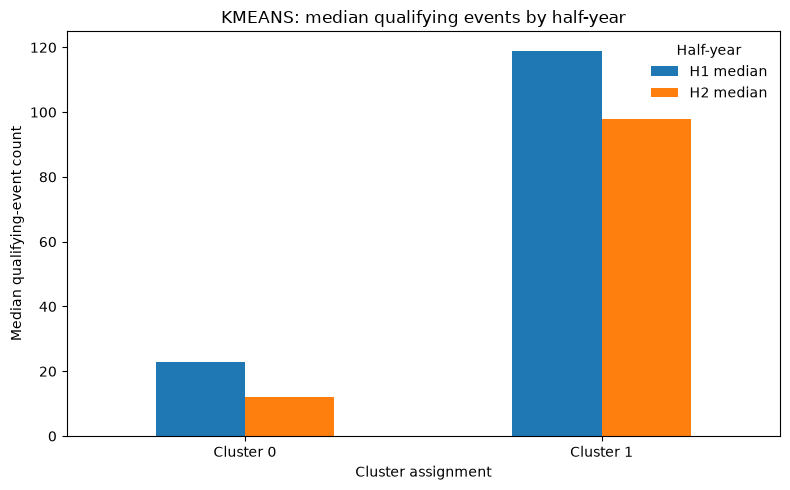

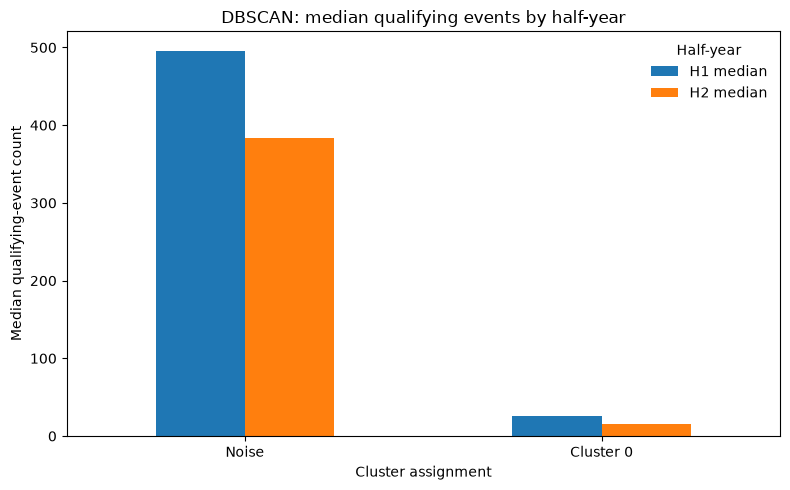

In [9]:
trend_features = [
    "qualifying_events_h1_2024",
    "qualifying_events_h2_2024",
]

for method in ["kmeans", "dbscan"]:
    trend = df.groupby(method)[trend_features].median()
    trend.columns = ["H1 median", "H2 median"]
    trend.index = [
        "Noise" if method == "dbscan" and group == -1 else f"Cluster {group}"
        for group in trend.index
    ]

    ax = trend.plot.bar(figsize=(8, 5), rot=0)
    ax.set_title(f"{method.upper()}: median qualifying events by half-year")
    ax.set_xlabel("Cluster assignment")
    ax.set_ylabel("Median qualifying-event count")
    ax.legend(title="Half-year", frameon=False)
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / f"{method}_activity_by_half_year.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

### Compare the two assignments

The cross-tabulation counts repositories by their K-means and DBSCAN assignments; the row-normalized version gives the proportions within each K-means group. It shows where the methods agree and where DBSCAN labels repositories as noise. Here, 99.8% of K-means cluster 0 and 82.2% of cluster 1 are in DBSCAN cluster 0. This is not a one-to-one match: DBSCAN produces one dense cluster plus noise, whereas K-means divides the full population into two groups.

In [10]:
overlap = pd.crosstab(
    df["kmeans"],
    df["dbscan"],
    rownames=["K-means"],
    colnames=["DBSCAN (-1 = noise)"],
)

print("Repository counts:")
display(overlap)

print("Proportion within each K-means cluster:")
display(overlap.div(overlap.sum(axis=1), axis=0).round(3))

Repository counts:


DBSCAN (-1 = noise),-1,0
K-means,,
0,11,6884
1,177,818


Proportion within each K-means cluster:


DBSCAN (-1 = noise),-1,0
K-means,,
0,0.002,0.998
1,0.178,0.822


## 5. Report-ready clustering analysis

The analysis compared K-means and DBSCAN on 7,890 repositories using 14 standardized activity features from 2024. The future inactivity outcome was excluded from model fitting and used only to describe the resulting groups.

| Method | Configuration and selection | Observed result |
|---|---|---|
| K-means | K=2 selected from K=1-8; highest sampled silhouette was 0.475; 20 initializations | Clusters contain 6,895 and 995 repositories |
| DBSCAN | Euclidean distance; `MIN_SAMPLES=28`; `EPS=3.218` selected from the k-distance knee and checked at nearby radii | One dense cluster of 7,702 repositories and 188 noise points |

K-means separated a large, lower-activity group from a smaller group with higher median event volume, broader participation, more activity in both half-years, and a more recent push. The smaller group had a 12.4% future inactivity rate, compared with 52.5% in the larger group. This pattern is consistent with the clusters representing different activity profiles in this sample; it does not establish that activity caused the later outcome.

DBSCAN produced one dense cluster and a small set of noise points at the selected settings. The noise group had higher medians on several activity features and a lower future inactivity rate (17.0%) than the dense cluster (48.2%). Noise therefore means relatively unusual local density under this feature space and parameter choice, not low activity, poor health, or likely archival.

The cross-tabulation shows substantial overlap: 99.8% of K-means cluster 0 and 82.2% of cluster 1 belong to DBSCAN cluster 0; the remaining 17.8% of cluster 1 is marked as noise. The methods do not recover equivalent partitions. K-means assigns every repository to one of two centroid-based groups, whereas DBSCAN's current parameters identify a single dense group rather than multiple density-based segments. This difference is consistent with their different assumptions and may indicate that the activity profiles form a continuum rather than several distinct dense groups; that explanation would require further testing.

The PCA scatterplots show the assignments after projection to two components, which retain 59.1% of the variance. They are useful for visual inspection but do not replace the full 14-dimensional clustering results. The sample also excludes repositories active in fewer than three months of 2024, limiting conclusions to the selected population.

Overall, the K-means solution provides two interpretable activity profiles, while DBSCAN primarily separates density outliers from one large group. These findings are exploratory, sensitive to the feature set and parameters, and do not demonstrate that either method predicts archival. A stronger claim would require testing multiple `K`, `EPS`, and `MIN_SAMPLES` settings and validating against an independent archival outcome.